# Applications II: Quantum Mechanics

Quantum mechanics is where numerical methods become indispensable: the Schrödinger equation can be solved exactly for only a handful of potentials. Everything else - real molecules, solids, nuclei, quantum devices - is done numerically.

- [A2.1 Bound states of the finite square well](#finite-well) - *root finding (Ch. 3)*
- [A2.2 The shooting method with Numerov's algorithm](#numerov) - *ODEs, shooting, bisection (Ch. 2, 3, 5)*
- [A2.3 The Hamiltonian as a matrix](#matrix) - *finite differences, eigenvalues (Ch. 4, 6)*
- [A2.4 Tunnelling splitting in a double well](#double-well) - *eigenvalues (Ch. 6)*
- [A2.5 The hydrogen atom](#hydrogen) - *eigenvalues on a non-trivial grid (Ch. 6)*
- [A2.6 Time evolution: a wavepacket hits a barrier](#tdse) - *Crank-Nicolson (Ch. 7), quadrature (Ch. 4)*
- [Projects](#projects)

Throughout we use units with $\hbar = m = 1$ (unless stated), so the time-independent Schrödinger equation (TISE) reads

$$-\frac12\psi''(x) + V(x)\psi(x) = E\psi(x).$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.linalg import eigh_tridiagonal
from scipy import sparse
from scipy.sparse.linalg import splu

# A2.1 Bound states of the finite square well <a class="anchor" id="finite-well"></a>
A particle in a well of depth $V_0$ and half-width $a$. Inside, $\psi\sim\cos(kx)$ or $\sin(kx)$ with $k=\sqrt{2mE'}/\hbar$ (measuring $E'$ from the bottom of the well); outside it decays like $e^{-\kappa|x|}$ with $\kappa=\sqrt{2m(V_0-E')}/\hbar$. Matching $\psi$ and $\psi'$ at $x=a$ gives, with the dimensionless variables $z=ka$ and $z_0=a\sqrt{2mV_0}/\hbar$:

$$\text{even states: } \tan z = \sqrt{\frac{z_0^2}{z^2}-1}, \qquad \text{odd states: } -\cot z = \sqrt{\frac{z_0^2}{z^2}-1}.$$

These **transcendental** equations are a textbook example where every undergraduate is told to "solve graphically". We can do better. The tangent has poles at $z=(2j+1)\pi/2$, so we bracket each root safely between consecutive poles and use `brentq`.

z0 = 8.0: 6 bound states
E/V0 = [0.96957 0.87873 0.72897 0.52365 0.27097 0.01064] (binding energy fraction)
z_n           = [1.3955 2.7859 4.1648 5.5214 6.8307 7.9573]
infinite well = [1.5708 3.1416 4.7124 6.2832 7.854  9.4248]


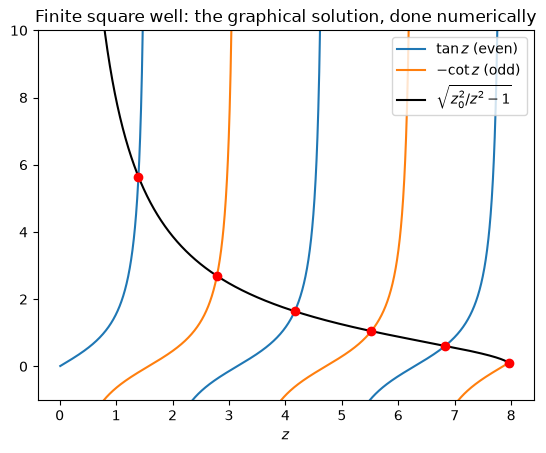

In [2]:
def finite_well_levels(z0):
    rhs = lambda z: np.sqrt(z0**2/z**2 - 1)
    even = lambda z: np.tan(z) - rhs(z)
    odd = lambda z: -1/np.tan(z) - rhs(z)
    roots, eps = [], 1e-12
    # the j-th state lives in z in [j pi/2, (j+1) pi/2], intersected with z < z0
    for j in range(int(2*z0/np.pi) + 1):
        lo, hi = j*np.pi/2 + eps, min((j + 1)*np.pi/2, z0) - eps
        if lo >= hi:
            break
        g = even if j % 2 == 0 else odd
        roots.append(brentq(g, lo, hi))
    return np.array(roots)

z0 = 8.0
z = finite_well_levels(z0)
print(f'z0 = {z0}: {len(z)} bound states')
print('E/V0 =', np.round(1 - (z/z0)**2, 5), '(binding energy fraction)')
# compare with the infinite well: z_n = n pi / 2
print('z_n           =', np.round(z, 4))
print('infinite well =', np.round(np.arange(1, len(z) + 1)*np.pi/2, 4))

zz = np.linspace(0.01, z0, 2000)
with np.errstate(invalid='ignore', divide='ignore'):
    tan, cot = np.tan(zz), -1/np.tan(zz)
tan[np.abs(tan) > 20] = np.nan; cot[np.abs(cot) > 20] = np.nan
plt.plot(zz, tan, label=r'$\tan z$ (even)'); plt.plot(zz, cot, label=r'$-\cot z$ (odd)')
plt.plot(zz, np.sqrt(z0**2/zz**2 - 1), 'k', label=r'$\sqrt{z_0^2/z^2-1}$')
plt.plot(z, np.sqrt(z0**2/z**2 - 1), 'ro')
plt.ylim(-1, 10); plt.xlabel('$z$'); plt.legend(); plt.title('Finite square well: the graphical solution, done numerically')
plt.show()

# A2.2 The shooting method with Numerov's algorithm <a class="anchor" id="numerov"></a>
For a general potential, write the TISE as $\psi'' = -k^2(x)\psi$ with $k^2(x) = 2(E - V(x))$. We could use RK4, but equations of the special form $\psi''=f(x)\psi$ (no first derivative) have a beautiful dedicated method. **Numerov's algorithm** is

$$\left(1+\tfrac{h^2}{12}k_{n+1}^2\right)\psi_{n+1} = 2\left(1-\tfrac{5h^2}{12}k_n^2\right)\psi_n - \left(1+\tfrac{h^2}{12}k_{n-1}^2\right)\psi_{n-1},$$

which is **6th-order** locally (4th-order globally) for only one evaluation of $k^2$ per step. It comes from applying the second-derivative stencil to $\psi$ and correcting its $h^2$ error term using the ODE itself.

**The eigenvalue shooting method.** For a bound state, $\psi$ must decay at both ends. For a trial energy $E$, start deep in the forbidden region with $\psi=0$ and a tiny slope, integrate across, and look at $\psi(x_\text{max})$. For most energies it diverges to $\pm\infty$; it **changes sign** as $E$ passes through an eigenvalue. So: scan $E$, bracket sign changes, and refine with bisection/`brentq` - Chapters 2 and 3 in action.

harmonic oscillator: [0.5 1.5 2.5 3.5 4.5]
quartic oscillator : [ 0.667986  2.393644  4.696795  7.33573  10.244308]


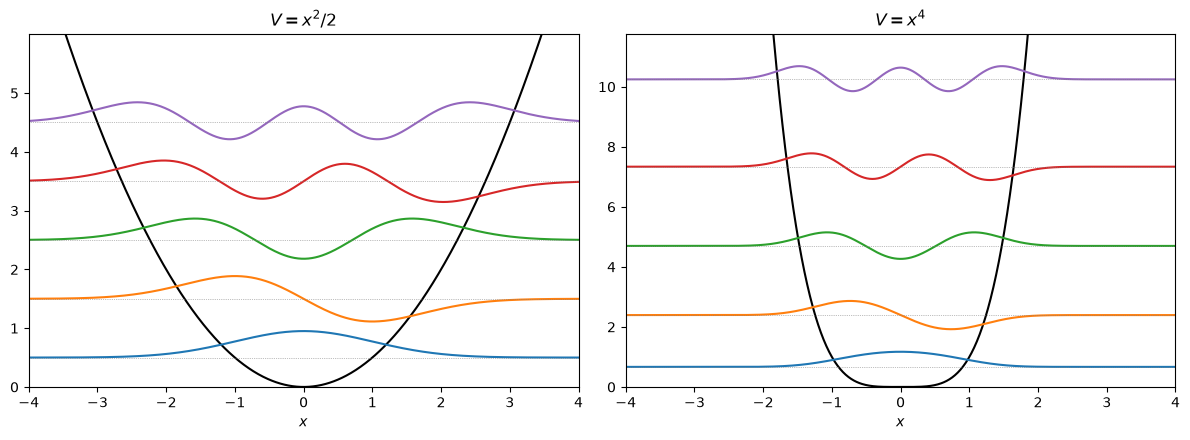

In [3]:
def numerov(k2, psi0, psi1, h):
    psi = np.zeros_like(k2)
    psi[0], psi[1] = psi0, psi1
    c = 1 + h**2*k2/12
    for n in range(1, len(k2) - 1):
        psi[n+1] = (2*(1 - 5*h**2*k2[n]/12)*psi[n] - c[n-1]*psi[n-1]) / c[n+1]
    return psi

def shoot(E, V, x):
    h = x[1] - x[0]
    return numerov(2*(E - V), 0.0, 1e-6, h)

def find_eigenvalues(V, x, E_grid):
    end = np.array([shoot(E, V, x)[-1] for E in E_grid])
    idx = np.where(np.sign(end[:-1]) != np.sign(end[1:]))[0]
    return np.array([brentq(lambda E: shoot(E, V, x)[-1], E_grid[i], E_grid[i+1], xtol=1e-13) for i in idx])

# Test on the harmonic oscillator V = x^2/2, exact E_n = n + 1/2
x = np.linspace(-6, 6, 1201)
V = 0.5*x**2
E_n = find_eigenvalues(V, x, np.linspace(0.1, 5, 60))
print('harmonic oscillator:', np.round(E_n, 8))

# Now something without an analytic solution: the quartic oscillator V = x^4
V4 = x**4
E4 = find_eigenvalues(V4, x, np.linspace(0.1, 12, 120))
print('quartic oscillator :', np.round(E4, 6))

def tame_tail(psi, E, V, x):
    """Even at an eigenvalue, round-off makes psi blow up deep in the right-hand forbidden
    region. Cut it off where |psi| is smallest beyond the classical turning point."""
    turning = np.where(V < E)[0][-1]
    cut = turning + np.argmin(np.abs(psi[turning:]))
    psi = psi.copy()
    psi[cut:] = 0
    return psi

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, Vx, Es, title in [(axes[0], V, E_n, r'$V = x^2/2$'), (axes[1], V4, E4, r'$V = x^4$')]:
    ax.plot(x, Vx, 'k')
    for E in Es:
        psi = tame_tail(shoot(E, Vx, x), E, Vx, x)
        psi /= np.sqrt(np.trapezoid(psi**2, x))
        ax.plot(x, E + 0.6*psi)
        ax.axhline(E, color='grey', lw=0.5, ls=':')
    ax.set_ylim(0, Es[-1] + 1.5); ax.set_xlim(-4, 4); ax.set_xlabel('$x$'); ax.set_title(title)
plt.tight_layout(); plt.show()

Why did we need `tame_tail`? Shooting *into* a classically forbidden region is unstable: the growing solution $e^{+\kappa x}$ swamps the decaying one, so even at an (almost) exact eigenvalue the far tail eventually explodes. The cure in professional codes is to shoot from *both* ends and match the logarithmic derivative $\psi'/\psi$ at a point in the middle.

# A2.3 The Hamiltonian as a matrix <a class="anchor" id="matrix"></a>
A completely different approach: discretise the whole equation at once. With the second-derivative stencil from Chapter 4,

$$-\frac{1}{2}\frac{\psi_{i+1}-2\psi_i+\psi_{i-1}}{h^2} + V_i\psi_i = E\psi_i,$$

the TISE becomes a **matrix eigenvalue problem** $H\boldsymbol\psi = E\boldsymbol\psi$ with $H$ tridiagonal:

$$H_{ii} = \frac{1}{h^2} + V_i,\qquad H_{i,i\pm1} = -\frac{1}{2h^2}.$$

The boundary condition $\psi=0$ at the ends of the box is built in. One call to an eigenvalue solver gives **all** the states at once. Because $H$ is symmetric and tridiagonal, `scipy.linalg.eigh_tridiagonal` is very fast even for $10^4$ points.

In [4]:
def solve_tise(V, x, n_states=10):
    h = x[1] - x[0]
    diag = 1/h**2 + V
    off = -0.5/h**2*np.ones(len(x) - 1)
    E, psi = eigh_tridiagonal(diag, off, select='i', select_range=(0, n_states - 1))
    psi /= np.sqrt(h)                       # normalise so that sum |psi|^2 h = 1
    return E, psi

for N in [100, 200, 400, 800]:
    xg = np.linspace(-8, 8, N)
    E, _ = solve_tise(0.5*xg**2, xg, 5)
    print(f'N = {N:>4}: E = {np.round(E, 6)}   max error = {np.max(np.abs(E - (np.arange(5) + 0.5))):.1e}')

N =  100: E = [0.499182 1.495907 2.489342 3.479471 4.466277]   max error = 3.4e-02
N =  200: E = [0.499798 1.498989 2.497371 3.494942 4.491702]   max error = 8.3e-03
N =  400: E = [0.49995  1.499749 2.499347 3.498743 4.497939]   max error = 2.1e-03
N =  800: E = [0.499987 1.499937 2.499837 3.499687 4.499486]   max error = 5.1e-04


The error falls by 4 each time $N$ doubles - second order, exactly as the stencil promises. (Richardson extrapolation from Chapter 4 would give 4th order for free!)

# A2.4 Tunnelling splitting in a double well <a class="anchor" id="double-well"></a>
The ammonia molecule NH$_3$ can have its nitrogen atom on either side of the plane of hydrogens: a symmetric **double-well** potential. Classically a low-energy particle is stuck in one well; quantum mechanically it tunnels, and the ground state splits into a symmetric and antisymmetric pair separated by a tiny energy $\Delta$. (In ammonia, $\Delta$ corresponds to a 24 GHz microwave transition - the basis of the first maser in 1954.)

Take $V(x) = V_0\left(x^2/b^2 - 1\right)^2$. The splitting is exponentially sensitive to the barrier height - a WKB calculation predicts $\Delta \propto e^{-\int\kappa\,dx}$. Let's see it numerically.

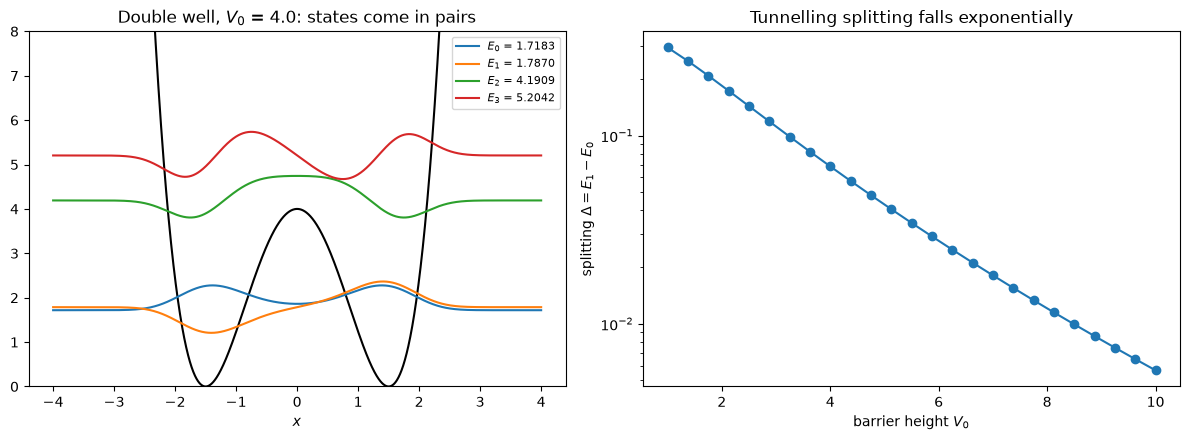

In [5]:
x = np.linspace(-4, 4, 2000)
b = 1.5
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))
V0 = 4.0
V = V0*(x**2/b**2 - 1)**2
E, psi = solve_tise(V, x, 4)
ax1.plot(x, V, 'k')
for n in range(4):
    ax1.plot(x, E[n] + 0.8*psi[:, n]*np.sign(psi[np.argmax(np.abs(psi[:, n])), n]), label=f'$E_{n}$ = {E[n]:.4f}')
ax1.set_ylim(0, 8); ax1.set_xlabel('$x$'); ax1.legend(fontsize=8); ax1.set_title(f'Double well, $V_0$ = {V0}: states come in pairs')

V0s = np.linspace(1, 10, 25)
splittings = []
for V0 in V0s:
    E, _ = solve_tise(V0*(x**2/b**2 - 1)**2, x, 2)
    splittings.append(E[1] - E[0])
ax2.semilogy(V0s, splittings, 'o-')
ax2.set_xlabel('barrier height $V_0$'); ax2.set_ylabel(r'splitting $\Delta = E_1 - E_0$')
ax2.set_title('Tunnelling splitting falls exponentially')
plt.tight_layout(); plt.show()

# A2.5 The hydrogen atom <a class="anchor" id="hydrogen"></a>
Writing $\psi = \frac{u(r)}{r}Y_\ell^m(\theta,\phi)$ reduces the 3D problem to a 1D radial equation (atomic units, $\hbar=m_e=e=4\pi\varepsilon_0=1$, energies in Hartree $=27.2$ eV):

$$-\frac12 u'' + \left[-\frac{1}{r} + \frac{\ell(\ell+1)}{2r^2}\right]u = Eu,\qquad u(0)=u(\infty)=0.$$

The exact energies are $E_n = -\frac{1}{2n^2}$, independent of $\ell$ (an "accidental" degeneracy from a hidden symmetry). The bound states extend to $r\sim 2n^2$ Bohr radii, so we need a long box - but the wavefunctions vary quickly near the nucleus. A uniform grid is wasteful; still, it works well enough to see the physics. (Project: switch to a logarithmic grid $r=e^s$.)

 l    n    numerical E     exact -1/(2n^2)
 0    1   -0.499922       -0.500000
 0    2   -0.124995       -0.125000
 0    3   -0.055555       -0.055556
 0    4   -0.031250       -0.031250
 1    2   -0.125002       -0.125000
 1    3   -0.055556       -0.055556
 1    4   -0.031250       -0.031250
 2    3   -0.055556       -0.055556
 2    4   -0.031250       -0.031250


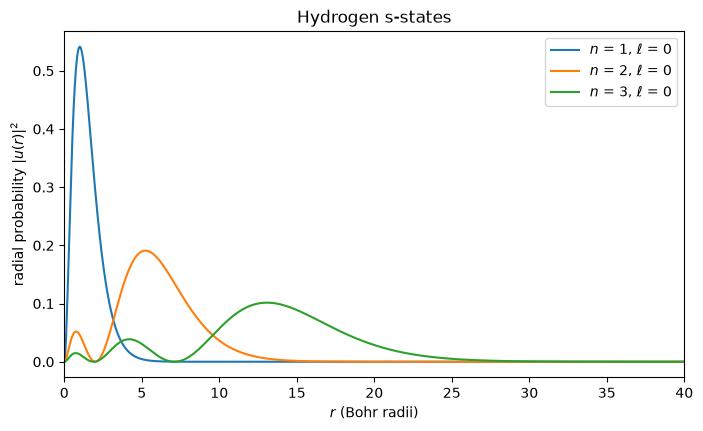

In [6]:
N, r_max = 6000, 150.0
r = np.linspace(r_max/N, r_max, N)
print(' l    n    numerical E     exact -1/(2n^2)')
fig, ax = plt.subplots(figsize=(8, 4.5))
for l in [0, 1, 2]:
    E, u = solve_tise(-1/r + l*(l + 1)/(2*r**2), r, 4 - l)
    for k, En in enumerate(E):
        n = k + l + 1
        print(f'{l:>2}   {n:>2}   {En:.6f}       {-0.5/n**2:.6f}')
    if l == 0:
        for k in range(3):
            ax.plot(r, u[:, k]**2, label=f'$n$ = {k+1}, $\\ell$ = 0')
ax.set_xlim(0, 40); ax.set_xlabel('$r$ (Bohr radii)'); ax.set_ylabel('radial probability $|u(r)|^2$')
ax.legend(); ax.set_title('Hydrogen s-states'); plt.show()

# A2.6 Time evolution: a wavepacket hits a barrier <a class="anchor" id="tdse"></a>
The time-dependent Schrödinger equation $i\partial_t\psi = H\psi$ has the formal solution $\psi(t+\Delta t) = e^{-iH\Delta t}\psi(t)$. The **Crank-Nicolson** method (Chapter 7.3) uses the approximation

$$e^{-iH\Delta t} \approx \frac{1 - \tfrac{i}{2}H\Delta t}{1 + \tfrac{i}{2}H\Delta t},
\qquad\text{i.e.}\qquad
\left(1 + \tfrac{i}{2}H\Delta t\right)\psi^{n+1} = \left(1 - \tfrac{i}{2}H\Delta t\right)\psi^n.$$

This "Cayley form" is not just stable: it is **exactly unitary**, so the total probability $\int|\psi|^2dx$ is conserved to machine precision, no matter how big $\Delta t$ is. Each step solves a (complex) tridiagonal system, so we pre-factorise the matrix once with a sparse LU decomposition.

We fire a Gaussian wavepacket with mean momentum $k_0$ at a rectangular barrier of height $V_0$ and width $w$, and measure the transmitted probability.

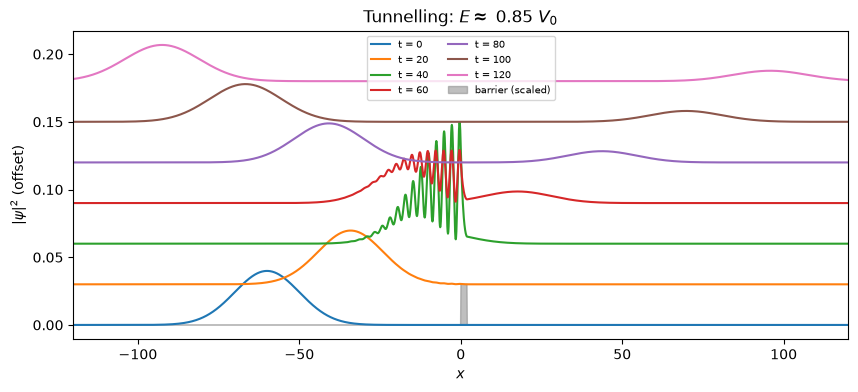

total probability at the end: 1.000000000000  (unitary!)
transmitted probability     : 0.2231


In [7]:
def crank_nicolson_tdse(psi0, V, x, dt, n_steps, store_every=20):
    h = x[1] - x[0]
    N = len(x)
    H = sparse.diags([-0.5/h**2*np.ones(N-1), 1/h**2 + V, -0.5/h**2*np.ones(N-1)], [-1, 0, 1], format='csc')
    I = sparse.identity(N, format='csc')
    A = splu((I + 0.5j*dt*H).tocsc())                 # factorise once ...
    B = (I - 0.5j*dt*H).tocsr()
    psi = psi0.astype(complex)
    frames = [psi.copy()]
    for n in range(1, n_steps + 1):
        psi = A.solve(B @ psi)                         # ... then each step is cheap
        if n % store_every == 0:
            frames.append(psi.copy())
    return np.array(frames)

x = np.linspace(-150, 250, 4000)
h = x[1] - x[0]
V0, w = 1.0, 2.0
V = np.where((x > 0) & (x < w), V0, 0.0)

def wavepacket(k0, x0=-60, sigma=10):
    psi = np.exp(-(x - x0)**2/(4*sigma**2) + 1j*k0*x)
    return psi/np.sqrt(np.sum(np.abs(psi)**2)*h)

k0 = 1.3                                              # mean energy k0^2/2 = 0.845 < V0
frames = crank_nicolson_tdse(wavepacket(k0), V, x, dt=0.1, n_steps=1200, store_every=200)

fig, ax = plt.subplots(figsize=(10, 4))
for i, f in enumerate(frames):
    ax.plot(x, np.abs(f)**2 + 0.03*i, label=f't = {i*20:.0f}')
ax.fill_between(x, 0, V*0.03, color='grey', alpha=0.5, label='barrier (scaled)')
ax.set_xlim(-120, 120); ax.set_xlabel('$x$'); ax.set_ylabel(r'$|\psi|^2$ (offset)'); ax.legend(fontsize=7, ncol=2)
ax.set_title(r'Tunnelling: $E \approx$ 0.85 $V_0$')
plt.show()

psi_end = frames[-1]
print(f'total probability at the end: {np.sum(np.abs(psi_end)**2)*h:.12f}  (unitary!)')
print(f'transmitted probability     : {np.sum(np.abs(psi_end[x > w])**2)*h:.4f}')

**Comparison with the textbook.** For a plane wave of energy $E<V_0$, the transmission coefficient through a rectangular barrier is

$$T(E) = \left[1 + \frac{V_0^2\sinh^2(\kappa w)}{4E(V_0-E)}\right]^{-1}, \quad \kappa=\sqrt{2(V_0-E)},$$

with the $\sinh\to\sin$ continuation for $E>V_0$. Our wavepacket contains a spread of momenta, so to compare fairly we use narrow-in-$k$ (wide-in-$x$) packets and scan $k_0$.

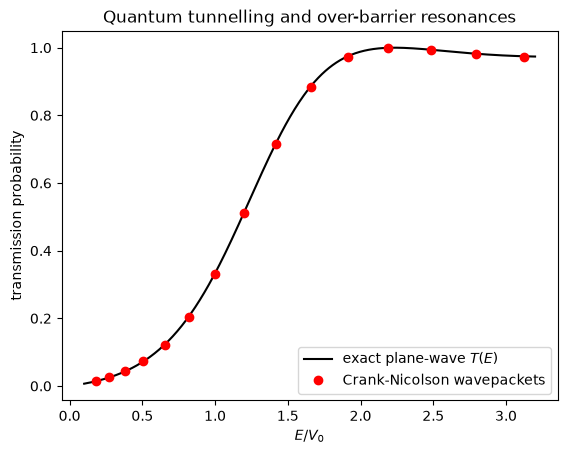

In [8]:
def T_exact(E):
    E = np.asarray(E, dtype=complex)
    kappa = np.sqrt(2*(V0 - E))
    return np.real(1/(1 + V0**2*np.sinh(kappa*w)**2/(4*E*(V0 - E))))

x = np.linspace(-400, 400, 8000)
h = x[1] - x[0]
V = np.where((x > 0) & (x < w), V0, 0.0)
k0s = np.linspace(0.6, 2.5, 15)
T_num = []
for k0 in k0s:
    psi0 = np.exp(-(x + 150)**2/(4*30**2) + 1j*k0*x)
    psi0 /= np.sqrt(np.sum(np.abs(psi0)**2)*h)
    t_end = 300/k0                                     # long enough for the packet to finish interacting
    n_steps = int(t_end/0.2)
    f = crank_nicolson_tdse(psi0, V, x, dt=0.2, n_steps=n_steps, store_every=n_steps)   # keep only start and end
    T_num.append(np.sum(np.abs(f[-1][x > w])**2)*h)

E = np.linspace(0.1, 3.2, 500)
plt.plot(E/V0, T_exact(E), 'k', label='exact plane-wave $T(E)$')
plt.plot(k0s**2/2/V0, T_num, 'ro', label='Crank-Nicolson wavepackets')
plt.xlabel('$E/V_0$'); plt.ylabel('transmission probability'); plt.legend()
plt.title('Quantum tunnelling and over-barrier resonances'); plt.show()

Note that even **above** the barrier ($E>V_0$) the transmission is not 100% - a purely quantum effect - and there are resonances where $T=1$ exactly (when a whole number of half-wavelengths fits across the barrier).

# Projects <a class="anchor" id="projects"></a>

1. **Split-operator FFT method.** An alternative to Crank-Nicolson uses $e^{-iH\Delta t}\approx e^{-iV\Delta t/2}e^{-iT\Delta t}e^{-iV\Delta t/2}$, where the kinetic factor is applied in momentum space using the FFT (Chapter 8.8). Implement it and compare with A2.6. Which is faster? Which is more accurate for the same $\Delta t$?
2. **Quantum harmonic oscillator coherent states.** Start a Gaussian wavepacket of width $1/\sqrt2$ displaced from the origin of $V=x^2/2$. Show that it oscillates without spreading, and that $\langle x\rangle(t)$ obeys Newton's law (Ehrenfest's theorem).
3. **A particle in a 2D box.** Build the 2D Hamiltonian on an $N\times N$ grid with `scipy.sparse.kron` and find the lowest eigenstates with `scipy.sparse.linalg.eigsh`. Compare a square box with a "stadium" shape and look at the nodal patterns (quantum chaos!).
4. **Kronig-Penney model.** Find the allowed energy bands for a periodic array of square barriers by solving $\cos(qL) = \cos(\alpha a)\cosh(\beta b) + \frac{\beta^2-\alpha^2}{2\alpha\beta}\sin(\alpha a)\sinh(\beta b)$: an energy is allowed if the right-hand side lies in $[-1,1]$. Plot the band structure.
5. **Anharmonic molecules.** Use the Morse potential $V(r) = D_e\left(1-e^{-a(r-r_e)}\right)^2$ with the parameters of H$_2$ to find its vibrational levels. How many bound states are there, and how does the spacing change near dissociation?

In [9]:
# Start working here